# Copy this notebook into usr/ and adjust to your needs.

In [1]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

In [2]:
### setup ###

import sys
# setup path to python virtual env & code directory
ecf_env_path = '/Users/kszczepaniak/Code/ecf-explorer-env'
lib_ecf_path = ecf_env_path + '/ecf-explorer/src'
sys.path.append(lib_ecf_path)

from utils.postprocess import load_clustering_results, select_reprseqs_to_display 
from utils.postprocess import load_features_data, select_features_to_display
from plots.plot_clustering_and_ecfs import plot_alignment_selected

workdir_path = '/Users/kszczepaniak/Data/Phage/phage-pp-workdir-ecftest-300'

In [3]:
# load dataset of hits with annotated clusters

clustering_results = load_clustering_results(workdir_path)
clustering_results

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster
0,reprseq30989,61,260,261,reprseq17791,43,198,200,19,108.2,1.200000e-12,98.7,1.900000e-16,0
1,reprseq30989,61,257,261,reprseq25394,60,214,215,16,115.8,1.700000e-13,98.9,2.700000e-17,0
2,reprseq30989,61,249,261,reprseq33575,43,210,217,16,70.4,2.200000e-06,96.7,3.400000e-10,0
3,reprseq30989,61,260,261,reprseq16961,43,216,218,15,108.0,2.000000e-12,98.7,3.200000e-16,0
4,reprseq30989,61,260,261,reprseq29975,45,231,233,12,107.4,3.400000e-12,98.6,5.500000e-16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
652820,reprseq35525,5,480,488,reprseq31745,3,457,487,23,590.9,4.200000e-72,100.0,6.400000e-76,0
652821,reprseq35525,5,467,488,reprseq18132,2,527,527,23,1126.4,6.000000e-140,100.0,9.000000e-144,0
652822,reprseq35525,6,466,488,reprseq21544,3,475,476,42,985.6,4.000000e-123,100.0,6.000000e-127,0
652823,reprseq35525,7,418,488,reprseq29665,18,412,432,15,321.6,1.900000e-37,100.0,2.900000e-41,0


In [4]:
# load features data
features_to_load = ['hhblits-pfam', 'hhblits-ecod', 'hhblits-cdd', 
                   'hhblits-uniclust30', 'hhblits-phrogs', 'hhblits-pdb',
                   'hhblits-pfam2', 'hhblits-pfam3']

features_data = load_features_data(workdir_path, features_to_load)
for fname, fdata in features_data.items():
    print(fname)
    display(fdata)

hhblits-pfam


,qname,qstart,qend,qlength,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq00010,90,209,209,22,149,255,14,73.6,7.300000e-07,96.9,1.500000e-10,PF13497.6 ; DUF4121 ; Domain of unknown functi...
1,reprseq00025,20,78,288,9,70,71,25,81.9,5.500000e-11,98.3,1.300000e-14,PF03118.15 ; RNA_pol_A_CTD ; Bacterial RNA pol...
2,reprseq00025,204,277,288,19,82,97,20,76.2,7.300000e-09,97.7,1.700000e-12,PF04447.12 ; DUF550 ; Protein of unknown funct...
3,reprseq00025,210,278,288,3,71,81,25,60.7,5.900000e-07,96.9,1.400000e-10,PF12643.7 ; MazG-like ; MazG-like family
4,reprseq00025,205,275,288,5,74,76,20,43.7,1.100000e-03,93.3,2.600000e-07,PF03819.17 ; MazG ; MazG nucleotide pyrophosph...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
154046,reprseq34461,2,124,174,2,158,182,9,66.8,2.300000e-07,97.1,5.500000e-11,PF11041.8 ; DUF2612 ; Protein of unknown funct...
154047,reprseq34462,3,157,925,7,150,150,21,90.0,3.800000e-08,97.5,8.300000e-12,PF12571.8 ; DUF3751 ; Phage tail-collar fibre ...
154048,reprseq34462,712,735,925,70,93,93,33,82.7,5.800000e-08,97.4,1.200000e-11,PF14928.6 ; S_tail_recep_bd ; Short tail fibre...
154049,reprseq34462,589,642,925,2,57,57,19,66.6,6.300000e-07,96.9,1.400000e-10,PF07484.12 ; Collar ; Phage Tail Collar Domain


hhblits-ecod


,qname,qstart,qend,qlength,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq00025,22,90,288,3,71,72,30,71.2,8.600000e-10,98.0,1.500000e-13,ECOD_000002989_e1lb2B1 | 102.1.1.25 | 1LB2 B:2...
1,reprseq00025,20,81,288,24,85,85,29,73.1,2.700000e-09,97.9,4.600000e-13,ECOD_001682737_e2maxA1 | 102.1.1.25 | 2MAX A:2...
2,reprseq00025,168,272,288,2,98,98,15,69.9,1.000000e-08,97.7,1.800000e-12,ECOD_001172157_e2gtaC2 | 159.1.2.1 | 2GTA C:2-...
3,reprseq00025,171,272,288,1,97,100,20,70.1,1.300000e-08,97.7,2.300000e-12,ECOD_000140562_e3obcA1 | 159.1.1.2 | 3OBC A:-7...
4,reprseq00025,22,84,288,4,66,67,35,63.5,1.700000e-08,97.6,3.000000e-12,ECOD_000002991_e1z3eB1 | 102.1.1.25 | 1Z3E B:2...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
455960,reprseq34447,94,131,133,1,36,98,6,35.7,1.100000e-02,90.6,1.300000e-06,ECOD_000154008_e4hv0B1 | 101.1.11.20 | 4HV0 B:...
455961,reprseq34447,89,131,133,2,43,81,12,33.3,1.100000e-02,90.4,1.400000e-06,ECOD_000002868_e1y9bA1 | 101.1.11.4 | 1Y9B A:3...
455962,reprseq34447,90,130,133,2,40,84,10,32.6,1.300000e-02,90.0,1.600000e-06,ECOD_001297406_e4q2uA1 | 101.1.11.13 | 4Q2U A:...
455963,reprseq34449,178,344,345,71,233,238,15,132.6,2.200000e-15,99.2,3.000000e-19,ECOD_000146201_e3kdrA1 | 4038.1.1.3 | 3KDR A:4...


hhblits-cdd


,qname,qstart,qend,qlength,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq00025,171,274,288,1,99,99,34,77.3,6.600000e-10,98.0,1.600000e-13,cd11542 NTP-PPase_u5; Nucleoside Triphosphate ...
1,reprseq00025,171,263,288,3,86,87,7,59.8,6.400000e-07,96.9,1.600000e-10,cd11543 NTP-PPase_u6; Nucleoside Triphosphate ...
2,reprseq00025,172,272,288,1,92,93,13,58.5,1.000000e-06,96.8,2.600000e-10,cd11531 NTP-PPase_BsYpjD; Nucleoside Triphosph...
3,reprseq00025,173,264,288,1,75,76,15,55.9,1.400000e-06,96.7,3.500000e-10,cd11540 NTP-PPase_u3; Nucleoside Triphosphate ...
4,reprseq00025,175,269,288,1,90,90,16,57.1,1.800000e-06,96.7,4.400000e-10,cd11537 NTP-PPase_RS21-C6_like; Nucleoside Tri...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
235848,reprseq34445,5,70,163,2,78,94,12,46.7,5.100000e-05,95.6,1.100000e-08,cd11527 NTP-PPase_dUTPase; Nucleoside Triphosp...
235849,reprseq34445,27,73,163,30,73,84,18,42.1,4.400000e-04,94.4,9.400000e-08,cd11546 NTP-PPase_His4; Nucleoside Triphosphat...
235850,reprseq34445,26,73,163,31,78,86,19,41.7,7.200000e-04,93.9,1.500000e-07,cd11547 NTP-PPase_HisE; Nucleoside Triphosphat...
235851,reprseq34445,26,73,163,29,76,84,13,40.9,9.700000e-04,93.6,2.000000e-07,cd11534 NTP-PPase_HisIE_like; Nucleoside Triph...


... (6 outputs left out)

hhblits-pfam2


,qname,qstart,qend,qlength,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq00010,90,209,209,22,149,255,14,73.6,7.300000e-07,96.9,1.500000e-10,PF13497.6 ; DUF4121 ; Domain of unknown functi...
1,reprseq00025,20,78,288,9,70,71,25,81.9,5.500000e-11,98.3,1.300000e-14,PF03118.15 ; RNA_pol_A_CTD ; Bacterial RNA pol...
2,reprseq00025,204,277,288,19,82,97,20,76.2,7.300000e-09,97.7,1.700000e-12,PF04447.12 ; DUF550 ; Protein of unknown funct...
3,reprseq00025,210,278,288,3,71,81,25,60.7,5.900000e-07,96.9,1.400000e-10,PF12643.7 ; MazG-like ; MazG-like family
4,reprseq00025,205,275,288,5,74,76,20,43.7,1.100000e-03,93.3,2.600000e-07,PF03819.17 ; MazG ; MazG nucleotide pyrophosph...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
154046,reprseq34461,2,124,174,2,158,182,9,66.8,2.300000e-07,97.1,5.500000e-11,PF11041.8 ; DUF2612 ; Protein of unknown funct...
154047,reprseq34462,3,157,925,7,150,150,21,90.0,3.800000e-08,97.5,8.300000e-12,PF12571.8 ; DUF3751 ; Phage tail-collar fibre ...
154048,reprseq34462,712,735,925,70,93,93,33,82.7,5.800000e-08,97.4,1.200000e-11,PF14928.6 ; S_tail_recep_bd ; Short tail fibre...
154049,reprseq34462,589,642,925,2,57,57,19,66.6,6.300000e-07,96.9,1.400000e-10,PF07484.12 ; Collar ; Phage Tail Collar Domain


hhblits-pfam3


,qname,qstart,qend,qlength,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq00010,90,209,209,22,149,255,14,73.6,7.300000e-07,96.9,1.500000e-10,PF13497.6 ; DUF4121 ; Domain of unknown functi...
1,reprseq00025,20,78,288,9,70,71,25,81.9,5.500000e-11,98.3,1.300000e-14,PF03118.15 ; RNA_pol_A_CTD ; Bacterial RNA pol...
2,reprseq00025,204,277,288,19,82,97,20,76.2,7.300000e-09,97.7,1.700000e-12,PF04447.12 ; DUF550 ; Protein of unknown funct...
3,reprseq00025,210,278,288,3,71,81,25,60.7,5.900000e-07,96.9,1.400000e-10,PF12643.7 ; MazG-like ; MazG-like family
4,reprseq00025,205,275,288,5,74,76,20,43.7,1.100000e-03,93.3,2.600000e-07,PF03819.17 ; MazG ; MazG nucleotide pyrophosph...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
154046,reprseq34461,2,124,174,2,158,182,9,66.8,2.300000e-07,97.1,5.500000e-11,PF11041.8 ; DUF2612 ; Protein of unknown funct...
154047,reprseq34462,3,157,925,7,150,150,21,90.0,3.800000e-08,97.5,8.300000e-12,PF12571.8 ; DUF3751 ; Phage tail-collar fibre ...
154048,reprseq34462,712,735,925,70,93,93,33,82.7,5.800000e-08,97.4,1.200000e-11,PF14928.6 ; S_tail_recep_bd ; Short tail fibre...
154049,reprseq34462,589,642,925,2,57,57,19,66.6,6.300000e-07,96.9,1.400000e-10,PF07484.12 ; Collar ; Phage Tail Collar Domain


In [5]:
# select representative proteins to display
reprseqs_to_display = [72, 30989, 22103]

# filter reprseq & features data for plot
selected_reprseq_data  = select_reprseqs_to_display(clustering_results, reprseqs_to_display)
selected_features_data = select_features_to_display(features_data, reprseqs_to_display)
selected_reprseq_data

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster
0,reprseq30989,61,260,261,reprseq17791,43,198,200,19,108.2,1.200000e-12,98.7,1.900000e-16,0
1,reprseq30989,61,257,261,reprseq25394,60,214,215,16,115.8,1.700000e-13,98.9,2.700000e-17,0
2,reprseq30989,61,249,261,reprseq33575,43,210,217,16,70.4,2.200000e-06,96.7,3.400000e-10,0
3,reprseq30989,61,260,261,reprseq16961,43,216,218,15,108.0,2.000000e-12,98.7,3.200000e-16,0
4,reprseq30989,61,260,261,reprseq29975,45,231,233,12,107.4,3.400000e-12,98.6,5.500000e-16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
647282,reprseq22103,783,819,869,reprseq20075,1446,1484,1887,26,71.2,1.100000e-02,90.7,1.300000e-06,1
647283,reprseq22103,783,792,869,reprseq05115,1279,1288,2127,50,107.2,1.000000e-07,97.4,1.200000e-11,1
647284,reprseq22103,786,822,869,reprseq18746,937,973,1022,33,60.9,1.200000e-02,90.6,1.300000e-06,1
647285,reprseq22103,828,862,869,reprseq07400,935,969,970,23,130.9,3.800000e-10,98.2,4.300000e-14,1


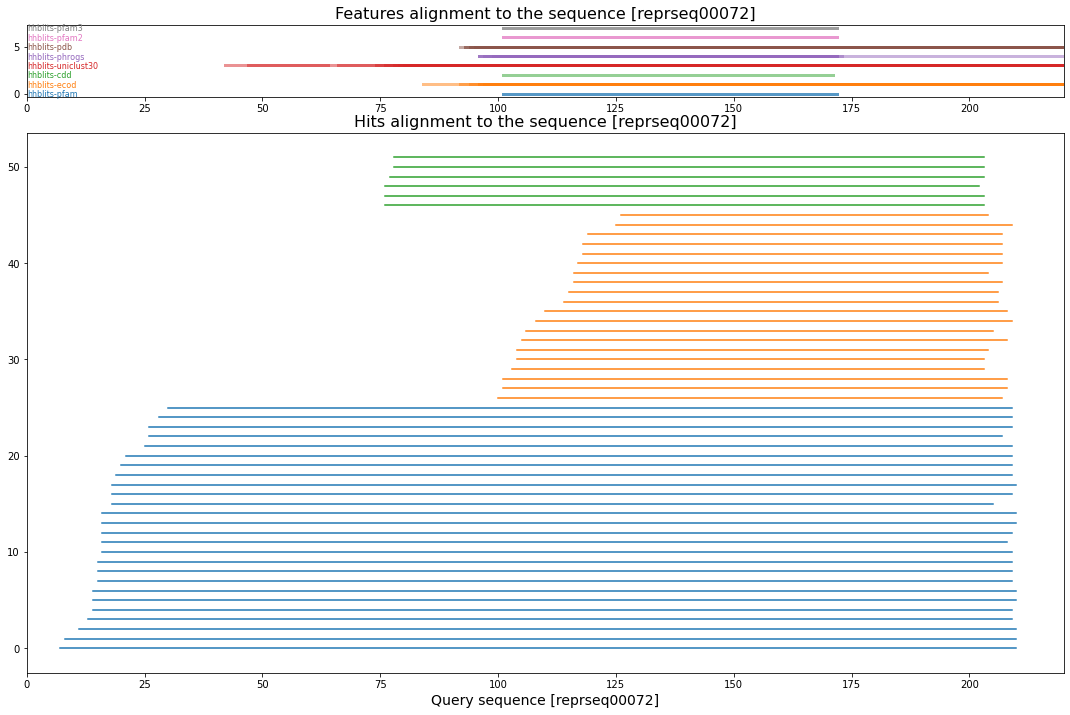

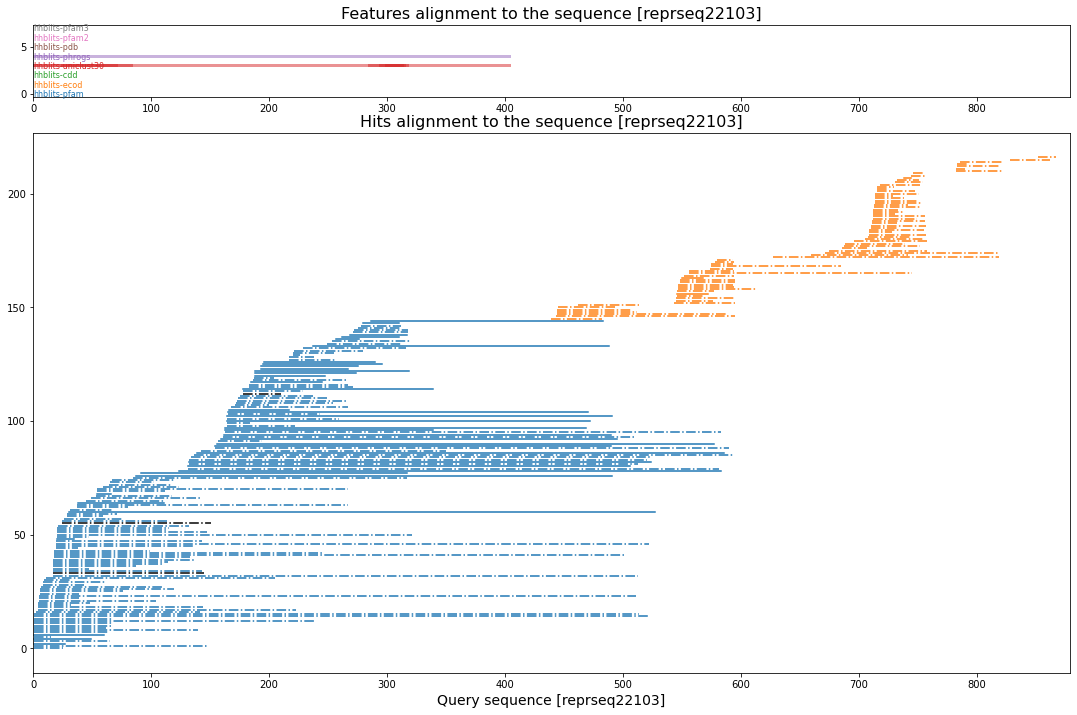

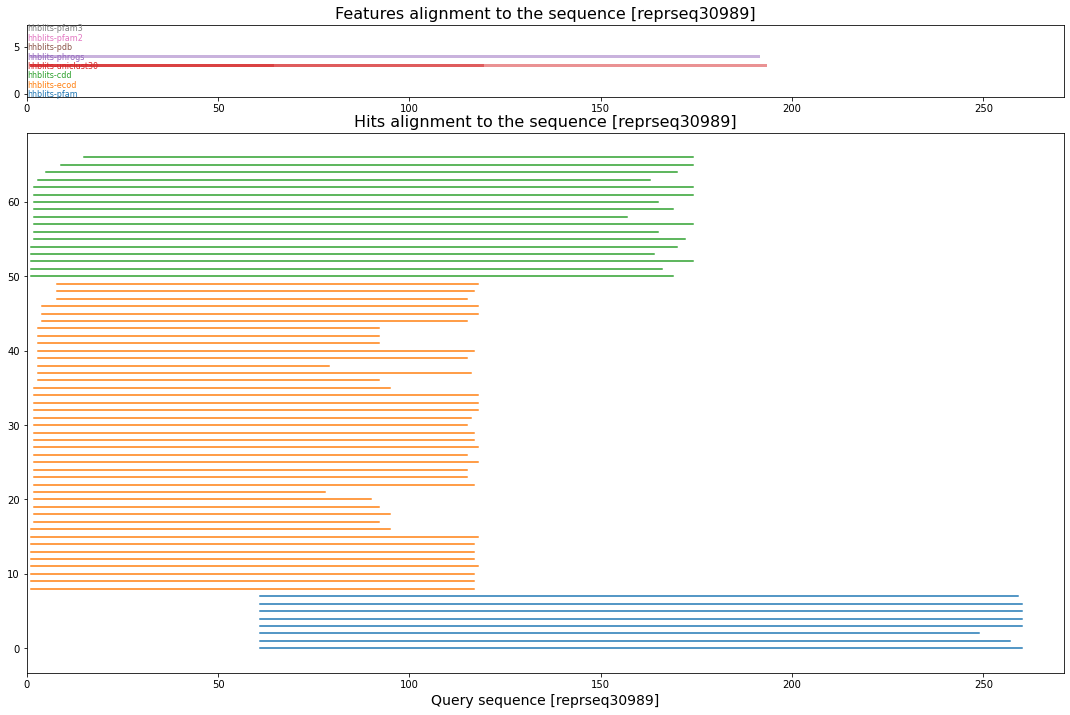

In [7]:
# plot required reprseqs
plot_alignment_selected(workdir_path, selected_reprseq_data, selected_features_data, save_figure=True)